# Convolving the $F_3^{\gamma Z}$ FK table with the PDF

Convolve the `HERA_F3_aZ` FK table with a PDF to predict $xF_3^{\gamma Z}$ for the HERA CC/NC dataset, and compare to data.

In [1]:
import pineappl
import numpy as np
import lhapdf
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
from eko import basis_rotation as br

## Load HERA data

In [2]:
# table 7 in https://arxiv.org/pdf/1506.06042
with open("HERA_xF3.json") as f:
    hera_data = json.load(f)

data = {"x": [], "Q2": [], "exp_cv": [], "exp_error": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["exp_error"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["exp_cv"].append(float(xF3))
data = pd.DataFrame(data)

data = {"x": [], "Q2": [], "exp_cv": [], "exp_error": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["exp_error"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["exp_cv"].append(float(xF3))
data = pd.DataFrame(data)

## Load FK table and kinematic prefactor

In [3]:
fk = pineappl.fk_table.FkTable.read("fk_tables/40000000/HERA_F3_aZ.pineappl.lz4")
pdfset = "NNPDF40_nnlo_as_01180"
bin_specs = np.array(fk.bin_limits())
q2 = np.unique(bin_specs[:, 0, 0])  # Q2 in the 1st dimension
x = np.unique(bin_specs[:, 1, 0])  # x in 2nd dimension

q2_max = max(q2)

mZ = 91.1876
sth2 = 0.23126
cth2 = 1 - sth2
kZ = data["Q2"]/((data["Q2"] + mZ ** 2) * 4 * cth2 * sth2)  # see Eq.2 in https://arxiv.org/pdf/1506.06042
prefactor = 2 / kZ


## Fixing all flavours but V3

In [4]:
channels = [c[0] for c in fk.channels()]  # evolution-basis PIDs, in fk.table()'s channel order
table = np.array(fk.table())              # shape (n_bins, n_channels, n_x)
xgrid = np.array(fk.x_grid())             # shape (n_x,): the FK table's own interpolation nodes
V3_ci = channels.index(203)               # 203 == V3 in eko's evol_basis_pids

M = np.array(br.rotate_flavor_to_evolution, dtype=float)  # evol_vector = M @ flavor_vector

Q0 = 1.65
Q02 = Q0 ** 2
assert np.isclose(fk.fac0(), Q02)

# load the baseline PDF (NNPDF4.0) that we will use to compute the offset from all channels except V3
baseline_pdf = lhapdf.mkPDF(pdfset, 0)

def evol_val(pid, x, pdf=baseline_pdf, Q02=Q02):
    """Computes contribution of a single evolution-basis PDF to the oveall prediction at Q0, for a given x.
    This is used to compute the offset from all channels except V3."""
    flavor_vec = np.array([pdf.xfxQ2(p, x, Q02) for p in br.flavor_basis_pids])
    return (M @ flavor_vec)[br.evol_basis_pids.index(pid)]

LHAPDF 6.5.5 loading /Users/jaco/miniconda3/envs/nnpdf_dev/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat


NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


In [5]:
# select the V3 channel and divide by xgrid to get the matrix W that multiplies V3(x, Q0)
W = table[:, V3_ci, :] / xgrid[None, :]  # shape (n_bins, n_x)

# build the offset from all other channels
offset = np.zeros(table.shape[0])
for ci, pid in enumerate(channels):
    if ci == V3_ci:
        continue
    vals = np.array([evol_val(pid, x) for x in xgrid])  # NNPDF4.0 at Q0 for this channel
    offset += (table[:, ci, :] / xgrid[None, :]) @ vals

# absorb the xF3^{gammaZ} prefactor so that `W @ V3 + offset` is the final prediction directly
prefactor_arr = np.asarray(prefactor)
W *= prefactor_arr[:, None]
offset *= prefactor_arr


In [6]:
# sanity check: plug NNPDF4.0's own V3 back in -> W @ V3 + offset must reproduce fk.convolve * prefactor exactly
v_V3_nnpdf40 = np.array([evol_val(203, x) for x in xgrid])
y_theory_roundtrip = W @ v_V3_nnpdf40 + offset

pred_ref = fk.convolve(pdg_convs=fk.convolutions, xfxs=[baseline_pdf.xfxQ2]) * prefactor_arr
print("max abs deviation from fk.convolve:", np.max(np.abs(y_theory_roundtrip - pred_ref)))


max abs deviation from fk.convolve: 3.3306690738754696e-16


### Usage

In [7]:
# @Richard, it is possible to define a custom V3 (vectorised over x), i.e. V3_func(x) -> x * V3(x, Q0), and then compute the predictions as
# v_V3_fit = V3_func(xgrid)
# predictions_fit = W @ v_V3_fit + offset

## Data vs. theory comparison

Predictions built from `W @ V3 + offset`, using NNPDF4.0's own $V_3$ for now (drop-in placeholder until the fit provides one).


In [8]:
# V3 = NNPDF4.0 for now; replace with a fitted V3_func(xgrid) later
# prefactor is already absorbed into W, offset
predictions = W @ v_V3_nnpdf40 + offset


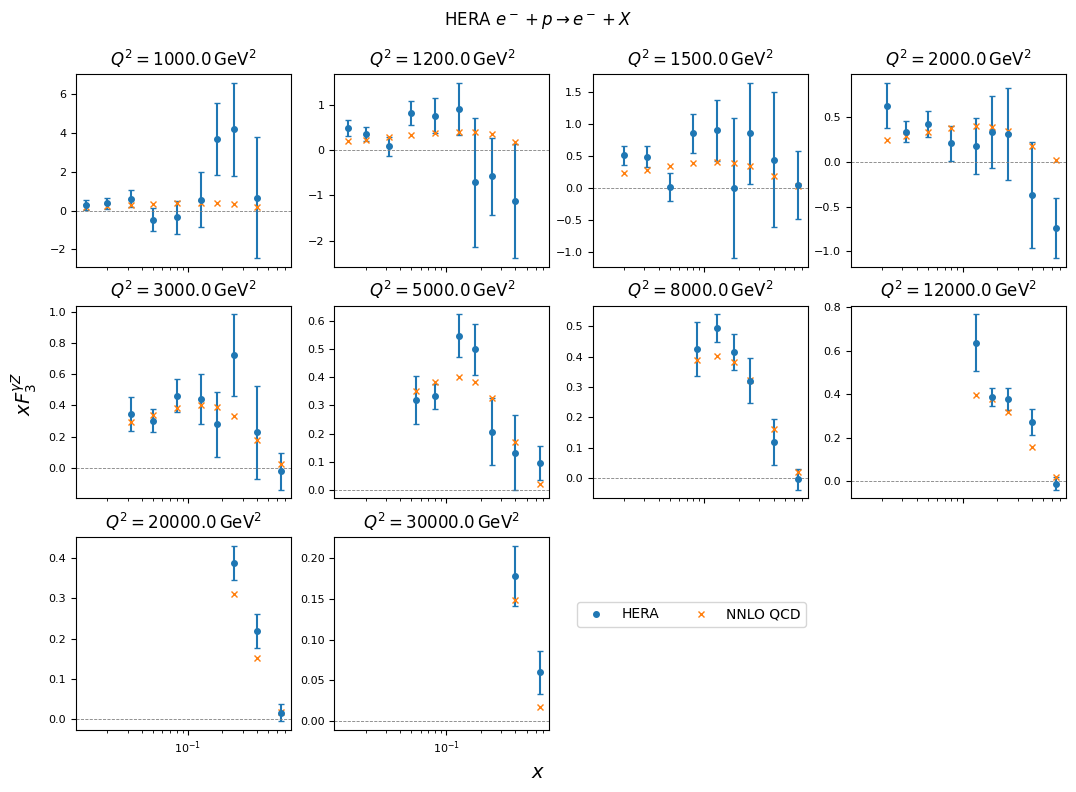

In [9]:
q2_values = np.sort(data["Q2"].unique())
n_used = len(q2_values)

fig, axes = plt.subplots(
    3, 4,
    figsize=(11, 8),
    sharex=True,
    sharey=False
)

fig.suptitle(r"HERA $e^- + p \to e^- + X$")

# Make panels touch
fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.9,
    wspace=0.2,
    hspace=0.2
)

axes_flat = axes.flatten()

exp_handle = None
th_handle = None

for i, (q2, ax) in enumerate(zip(q2_values, axes_flat)):
    dat = data[data["Q2"] == q2]

    # Plot data
    eb = ax.errorbar(
        dat["x"], dat["exp_cv"],
        yerr=dat["exp_error"],
        fmt="o", capsize=2, ms=4
    )
    if exp_handle is None:
        exp_handle = eb[0]

    (pth,) = ax.plot(dat["x"], predictions[data["Q2"] == q2], "x", ms=5)
    if th_handle is None:
        th_handle = pth

    # Log axis
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

    # Zero line
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)

    ax.set_title(f"$Q^2 = {q2} \\, \\mathrm{{GeV}}^2$")

    # Tick formatting
    ax.tick_params(axis="both", labelsize=8)

# Remove unused axes
for ax in axes_flat[n_used:]:
    fig.delaxes(ax)


# Global axis labels
fig.text(0.5, 0.02, r"$x$", ha="center", fontsize=14)
fig.text(0.02, 0.5, r"$xF_3^{\gamma Z}$", va="center",
         rotation="vertical", fontsize=14)

# Legend
fig.legend(
    handles=[exp_handle, th_handle],
    labels=["HERA", "NNLO QCD"],
    loc="lower right",
    ncols=2,
    frameon=True,
    bbox_to_anchor=(0.75, 0.2),
)


In [10]:
# compute the chi2
chi2 = np.sum(((predictions - data["exp_cv"]) / data["exp_error"]) ** 2)
print(f"Chi2: {chi2:.2f} / {len(data)} = {chi2/len(data):.2f}")


Chi2: 80.49 / 67 = 1.20
